In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"data/raw/cardata.csv")
df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [2]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Price,2059.0,1.702992e+06,2.419881e+06,49000.0,484999.00,825000.0,1925000.0,35000000.0
Year,2059.0,2.016425e+03,3.363564e+00,1988.0,2014.00,2017.0,2019.0,2022.0
Kilometer,2059.0,5.422471e+04,5.736172e+04,0.0,29000.00,50000.0,72000.0,2000000.0
Length,1995.0,4.280861e+03,4.424585e+02,3099.0,3985.00,4370.0,4629.0,5569.0
Width,1995.0,1.767992e+03,1.352658e+02,1475.0,1695.00,1770.0,1831.5,2220.0
Height,1995.0,1.591735e+03,1.360740e+02,1165.0,1485.00,1545.0,1675.0,1995.0
Seating Capacity,1995.0,5.306266e+00,8.221701e-01,2.0,5.00,5.0,5.0,8.0
Fuel Tank Capacity,1946.0,5.200221e+01,1.511020e+01,15.0,41.25,50.0,60.0,105.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   str    
 1   Model               2059 non-null   str    
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   str    
 6   Transmission        2059 non-null   str    
 7   Location            2059 non-null   str    
 8   Color               2059 non-null   str    
 9   Owner               2059 non-null   str    
 10  Seller Type         2059 non-null   str    
 11  Engine              1979 non-null   str    
 12  Max Power           1979 non-null   str    
 13  Max Torque          1979 non-null   str    
 14  Drivetrain          1923 non-null   str    
 15  Length              1995 non-null   float64
 16  Width            

## Missing Values

In [4]:
missing = df.isnull().sum()

missing_percent = (missing / len(df))*100 .__round__(1)
missing_df = pd.DataFrame({
    "missing_count" : missing,
    "missing_percent" : missing_percent.round(2)
})

missing_df.sort_values(by="missing_count" , ascending=False)

,missing_count,missing_percent
Drivetrain,136,6.61
Fuel Tank Capacity,113,5.49
Max Torque,80,3.89
Engine,80,3.89
Max Power,80,3.89
Height,64,3.11
Width,64,3.11
Length,64,3.11
Seating Capacity,64,3.11
Price,0,0.00


<Axes: >

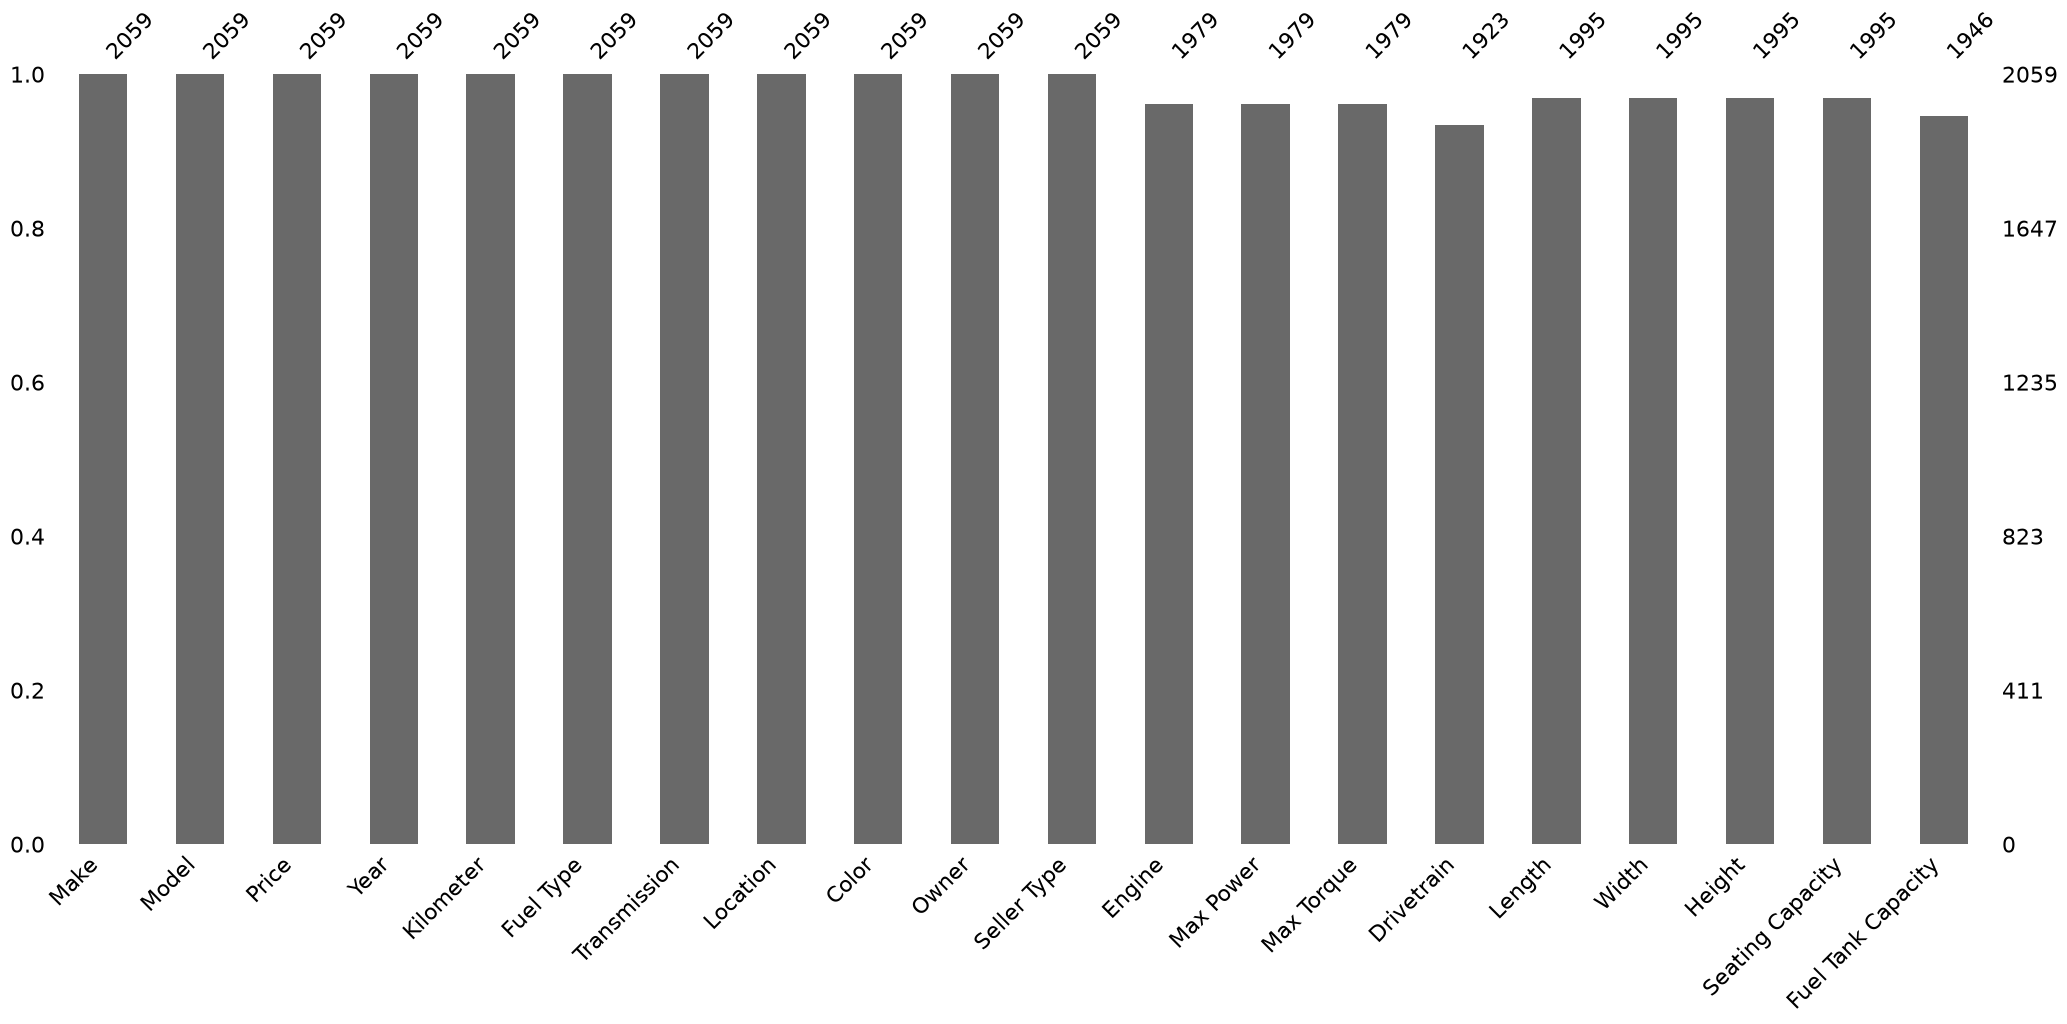

In [5]:
import missingno as msno

msno.bar(df)

## Feature distribution

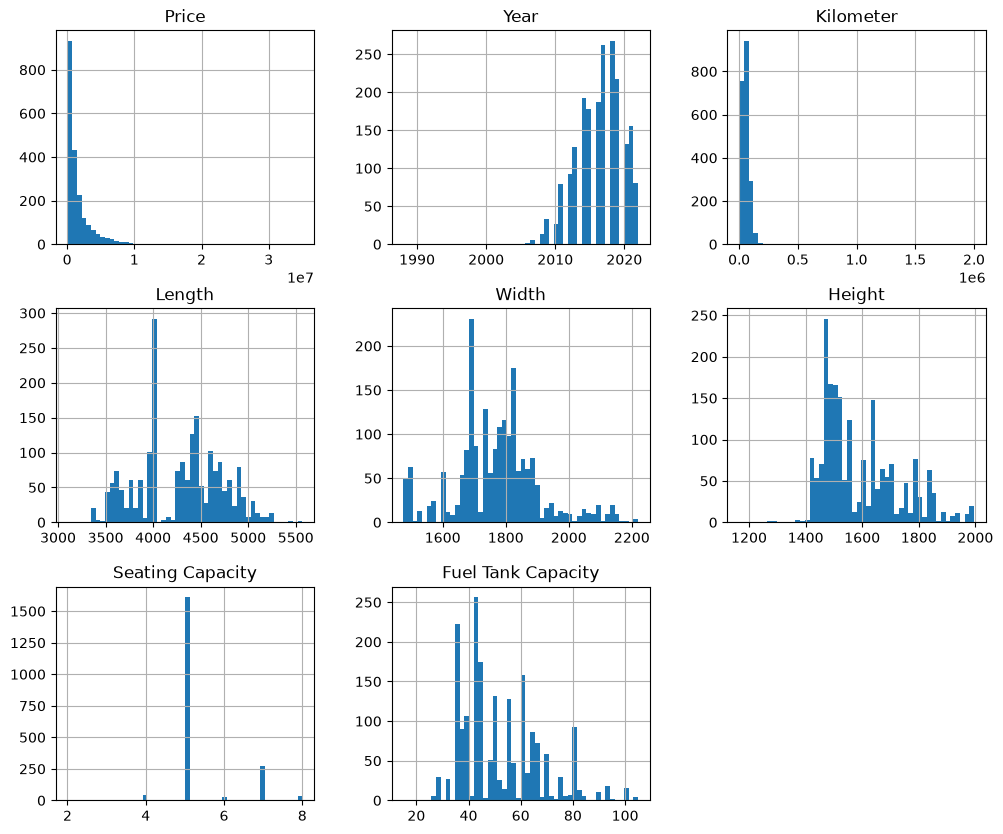

In [6]:
df.hist(bins=50 , figsize=(12,10))
plt.show()

In [7]:
df.sort_values('Kilometer',ascending=False)[['Make','Model','Year','Kilometer','Price']].head(20)

,Make,Model,Year,Kilometer,Price
1125,Renault,Duster 110 PS RXZ 4X2 MT Diesel,2016,2000000,450000
1866,Hyundai,Verna 1.6 CRDI SX,2018,925000,925000
1515,Hyundai,Creta SX 1.6 AT CRDi,2018,440000,1240000
1992,Toyota,Innova 2.0 G1 BS-IV,2010,261236,555000
733,Audi,A6 3.0 TDI quattro Premium,2012,240000,1650000
1628,Toyota,Innova 2.5 V 7 STR,2012,222000,960000
1991,Toyota,Fortuner 2.8 4x4 AT [2016-2020],2017,219000,2750000
181,Toyota,Fortuner 3.0 4x4 MT,2014,211000,1675000
134,BMW,5-Series 520d Sedan,2013,195000,1490000
388,Tata,Grande GX,2011,192326,199000


In [8]:
df.shape

(2059, 20)

## Correlation of feature's

In [9]:
corr_matrix = df.corr(numeric_only = True)
corr_matrix['Price'].sort_values(ascending=False)

Price                 1.000000
Fuel Tank Capacity    0.584631
Width                 0.563996
Length                0.556741
Year                  0.311400
Height                0.075080
Seating Capacity     -0.038524
Kilometer            -0.150825
Name: Price, dtype: float64

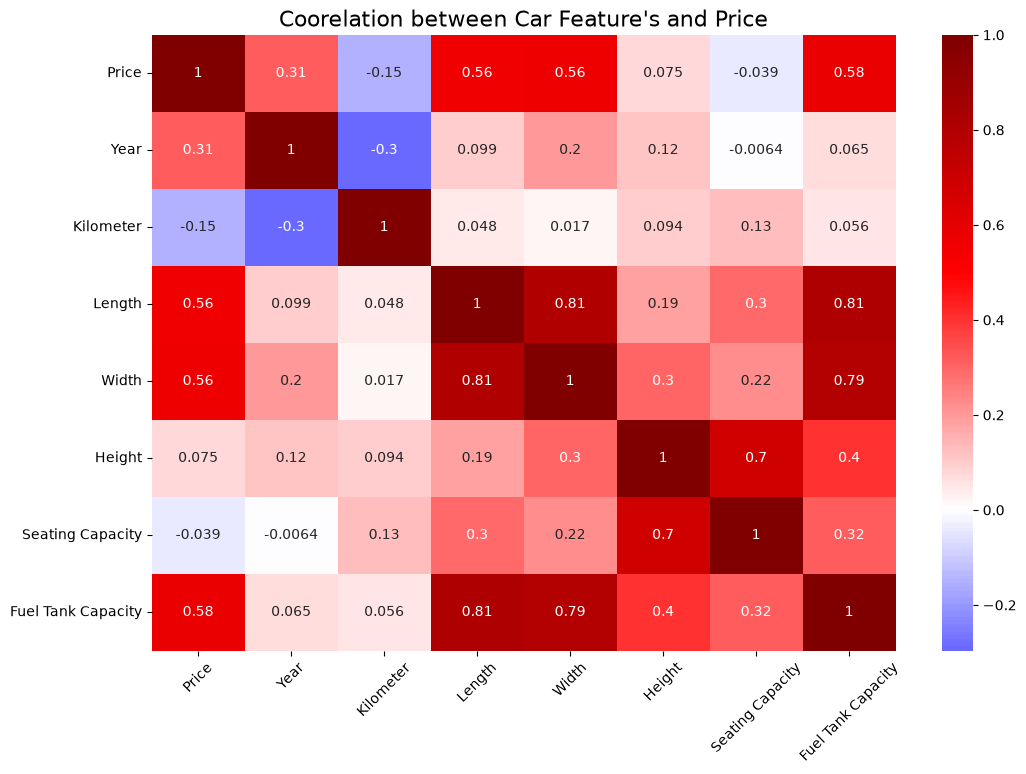

In [10]:
import seaborn as sns

plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix , annot=True, cmap="seismic",center=0)
plt.title("Coorelation between Car Feature's and Price",fontsize=16)
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='Fuel Tank Capacity', ylabel='Price'>

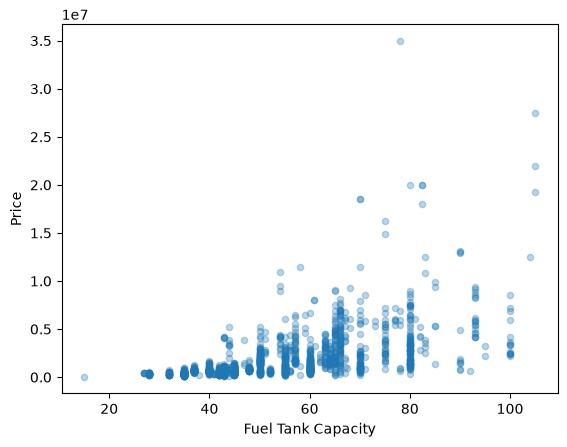

In [11]:
df.plot(kind='scatter', x='Fuel Tank Capacity', y='Price', alpha=0.3)

<Axes: >

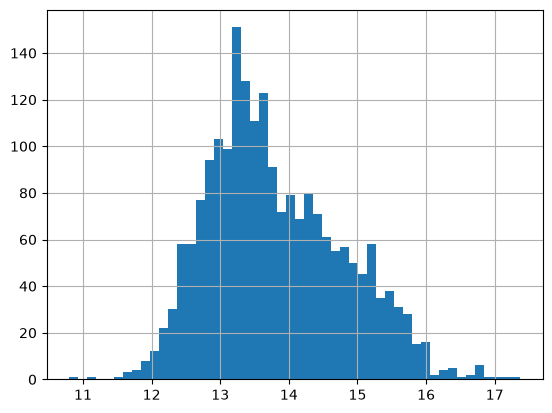

In [12]:
import numpy as np
np.log1p(df['Price']).hist(bins=50)

## Splitting data into training and testing data

In [13]:
from sklearn.model_selection import train_test_split

train_set , test_set  = train_test_split(df, test_size=0.2 , random_state=42)
train_set.shape, test_set.shape

((1647, 20), (412, 20))

<Axes: >

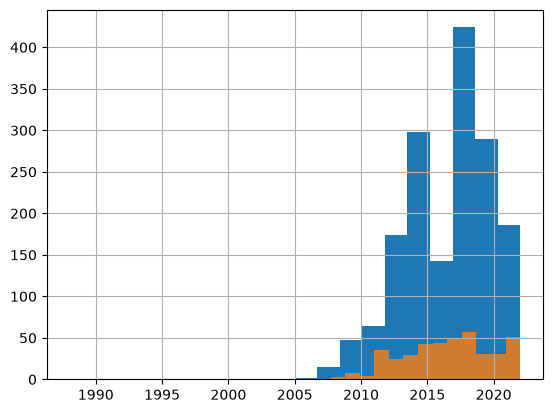

In [14]:
train_set['Year'].hist(bins=20)
test_set['Year'].hist(bins=20, alpha=0.8)

## Binning Year for stratified Sampling

 Created 'year_cat' using pd.cut to convert continuous 'Year' into categorical bins.
 This helps in performing stratified sampling during train-test split.

 Bins represent ranges of car manufacturing years:
 * 1987–2012 → Category 1 (older cars)
 * 2012–2015 → Category 2
 * 2015–2018 → Category 3
 * 2018–2020 → Category 4
 * 2020+     → Category 5 (newer cars)

 np.inf ensures that all values greater than 2020 are included in the last bin.

 Purpose:
 - Preserve distribution of car age in both train and test sets
 - Avoid biased sampling (e.g., too many new cars in test set)

 'year_cat' is only used for stratification and will be removed later.

In [15]:
df['year_cat'] = pd.cut(df['Year'],
                        bins=[1987, 2012, 2015, 2018,2020,np.inf],
                        labels=[1,2,3,4,5]
                        )

In [16]:
train_set, test_set = train_test_split(df, test_size=0.2, stratify=df['year_cat'],random_state=42)
train_set.shape, test_set.shape

((1647, 21), (412, 21))

In [17]:
train_set['year_cat'].value_counts(normalize=True).sort_index()

year_cat
1    0.125076
2    0.241651
3    0.347905
4    0.170006
5    0.115361
Name: proportion, dtype: float64

In [18]:
test_set['year_cat'].value_counts(normalize=True).sort_index()


year_cat
1    0.123786
2    0.242718
3    0.349515
4    0.169903
5    0.114078
Name: proportion, dtype: float64

In [19]:
train_set = train_set.drop('year_cat', axis=1)
test_set = test_set.drop('year_cat',axis=1)
df = df.drop('year_cat', axis=1)

In [20]:
car = train_set.copy()
car.corr(numeric_only = True)['Price'].sort_values(ascending=False)

Price                 1.000000
Fuel Tank Capacity    0.574316
Width                 0.551328
Length                0.548353
Year                  0.300934
Height                0.056084
Seating Capacity     -0.065782
Kilometer            -0.141173
Name: Price, dtype: float64

In [21]:
import re

def extract_number(text):
    if pd.isna(text):
        return np.nan
    match = re.search(r'[\d.]+', str(text))
    return float(match.group()) if match else np.nan

car['engine_cc'] = car['Engine'].apply(extract_number)
car['max_power_bhp'] = car['Max Power'].apply(extract_number)
car['max_torque_nm'] = car['Max Torque'].apply(extract_number)

car[['Engine', 'engine_cc', 'Max Power', 'max_power_bhp', 'Max Torque', 'max_torque_nm']].head()

,Engine,engine_cc,Max Power,max_power_bhp,Max Torque,max_torque_nm
826,1373 cc,1373.0,91 bhp @ 6000 rpm,91.0,130 Nm @ 4000 rpm,130.0
409,NaN,NaN,NaN,NaN,NaN,NaN
618,814 cc,814.0,56@5500,56.0,75@4000,75.0
845,1199 cc,1199.0,89 bhp @ 6000 rpm,89.0,110 Nm @ 4800 rpm,110.0
498,1197 cc,1197.0,83 bhp @ 6000 rpm,83.0,115 Nm @ 4000 rpm,115.0


In [22]:
car.corr(numeric_only= True)['Price'].sort_values(ascending= False)

Price                 1.000000
max_power_bhp         0.790168
max_torque_nm         0.661961
engine_cc             0.624075
Fuel Tank Capacity    0.574316
Width                 0.551328
Length                0.548353
Year                  0.300934
Height                0.056084
Seating Capacity     -0.065782
Kilometer            -0.141173
Name: Price, dtype: float64

In [23]:
car = train_set.drop('Price', axis = 1)
car_label = train_set['Price'].copy()

In [24]:
car['Fuel Type'].value_counts()

Fuel Type
Diesel          838
Petrol          762
CNG              33
Electric          5
LPG               4
Hybrid            3
Petrol + LPG      1
Petrol + CNG      1
Name: count, dtype: int64

In [25]:
car['Make'].value_counts()

Make
Maruti Suzuki    350
Hyundai          274
Mercedes-Benz    136
Honda            124
Audi             106
Toyota           105
Mahindra         100
BMW               95
Volkswagen        42
Renault           41
Tata              37
Skoda             34
Ford              33
Land Rover        26
Kia               18
Jaguar            17
Jeep              15
MG                13
Nissan            13
Porsche           13
Volvo             12
MINI               9
Lexus              6
Chevrolet          6
Datsun             6
Mitsubishi         4
Rolls-Royce        3
Isuzu              2
Fiat               2
Ssangyong          2
Ferrari            1
Maserati           1
Lamborghini        1
Name: count, dtype: int64

In [26]:
from sklearn.base import BaseEstimator , TransformerMixin

class EngineSpecExtractor(BaseEstimator , TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self,X):
        X = X.copy()
        X['engine_cc'] = X['Engine'].apply(extract_number)
        X['max_power_bhp'] = X['Max Power'].apply(extract_number)
        X['max_torque_nm'] = X['Max Torque'].apply(extract_number)
        return X.drop(columns = ['Engine', 'Max Power', 'Max Torque'])

In [27]:
extractor = EngineSpecExtractor()
car_test = extractor.transform(car)
car_test.head()

,Make,Model,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,engine_cc,max_power_bhp,max_torque_nm
826,Maruti Suzuki,Ciaz Delta 1.4 MT,2018,46000,Petrol,Manual,Noida,White,First,Individual,FWD,4490.0,1730.0,1485.0,5.0,43.0,1373.0,91.0,130.0
409,Maruti Suzuki,Wagon R VXi 1.0 [2019-2019],2018,40000,Petrol,Manual,Kanpur,White,First,Individual,NaN,3655.0,1620.0,1675.0,5.0,32.0,NaN,NaN,NaN
618,Hyundai,Eon Magna [2011-2012],2013,63000,Petrol,Manual,Ludhiana,White,Second,Individual,NaN,3495.0,1550.0,1500.0,5.0,32.0,814.0,56.0,75.0
845,Honda,Jazz V Petrol,2017,45000,Petrol,Manual,Delhi,Grey,First,Individual,FWD,3955.0,1694.0,1544.0,5.0,40.0,1199.0,89.0,110.0
498,Maruti Suzuki,Baleno Zeta 1.2,2021,22000,Petrol,Manual,Raipur,Blue,First,Individual,FWD,3995.0,1745.0,1500.0,5.0,37.0,1197.0,83.0,115.0


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.compose import make_column_selector as selector

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('std_scaler', StandardScaler()),
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown = 'ignore')),
])

preproces = ColumnTransformer([
    ('num', num_pipeline , selector(dtype_include=['int64', 'float64'])),
    ('cat', cat_pipeline , selector(dtype_include=['object']))
])

full_pipeline = Pipeline([
    ('spec_extractro', EngineSpecExtractor()),
    ('preprocess', preproces),
])

In [29]:
car_prepared = full_pipeline.fit_transform(car)
car_prepared.shape

(1647, 1065)

In [32]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(car_prepared , car_label)

some_data = car.iloc[:5]
some_labels = car_label.iloc[:5]
some_data_prepared = full_pipeline.transform(some_data)
print("predictions", lin_reg.predict(some_data_prepared))
print("actual :", list(some_labels))

predictions [735051.52028845 122033.25554511 179259.23797314 533211.86777725
 885287.97359919]
actual : [721000, 440000, 190000, 565000, 825000]


In [36]:
from sklearn.metrics import mean_squared_error
car_predictions = lin_reg.predict(car_prepared)
lin_mse = mean_squared_error(car_label, car_predictions)
lin_rmse = np.sqrt(lin_mse)
lin_rmse

np.float64(242084.16046921315)

In [35]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = RandomForestRegressor(random_state=42)
forest_reg.fit(car_prepared, car_label)

car_predictions = forest_reg.predict(car_prepared)
forest_mse = mean_squared_error(car_label, car_predictions)
forest_rmse = np.sqrt(forest_mse)
forest_rmse

np.float64(351290.5303700679)

In [38]:
car_prepared.shape[0], len(car_label)

(1647, 1647)

In [39]:
from sklearn.model_selection import cross_val_score

lin_scores = cross_val_score(lin_reg, car_prepared, car_label,
                              scoring="neg_mean_squared_error", cv=10)
lin_rmse_scores = np.sqrt(-lin_scores)

forest_scores = cross_val_score(forest_reg, car_prepared, car_label,
                                 scoring="neg_mean_squared_error", cv=10)
forest_rmse_scores = np.sqrt(-forest_scores)

In [40]:
def display_scores(scores, name):
    print(f"{name}")
    print("Scores:", scores)
    print("Mean:", scores.mean())
    print("Std:", scores.std())
    print()

display_scores(lin_rmse_scores, "Linear Regression")
display_scores(forest_rmse_scores, "Random Forest")

Linear Regression
Scores: [1746236.78353977 3614864.04431582 2050188.86722983 1684182.62388531
 1529070.92348781 2345506.96063553 1850895.93810967 1634041.30498935
 2896751.96857423  893191.24938126]
Mean: 2024493.066414858
Std: 727663.3034820661

Random Forest
Scores: [ 491888.26171578 1228466.37051859  937625.29862691  531940.73675427
  799444.79095651 1624834.17736904 1144447.20139171  495644.45017963
  887512.36617585  550549.85219617]
Mean: 869235.3505884461
Std: 358174.41586412344

